# EfficientViT on CheXpert (3-label multi-label)

Implementation of **EfficientViT: Memory Efficient Vision Transformer with Cascaded Group Attention** (Liu et al., CVPR 2023) in PyTorch, trained **from scratch**.

What is implemented (Fig. 6 and Table 1 of the paper):
- **Overlapping patch embedding** (four stride-2 convs = 16x16 patches)
- **Sandwich-layout block** (Eq. 1): DWConv token interaction + FFN -> **one** self-attention layer -> DWConv + FFN. FFN expansion ratio 2, BatchNorm, ReLU
- **Cascaded Group Attention** (Eq. 2-3): each head gets a different channel split; head j adds the output of head j-1 to its input; token-interaction DWConv after the Q projection; Q/K dim 16, V dim = channels per head (parameter reallocation)
- **EfficientViT subsample block** (inverted residual with SE instead of attention)
- Variants **M0-M5** from Table 1 (choose with `VARIANT`)

**Fidelity notes.** The paper does not list per-head DWConv kernel sizes, the attention window size, or the relative-position bias; I follow the official code's choices (kernels 5/7/3, window 7, learned relative bias). I wrote this from the paper and my memory of the official code, so small details may differ from the released code.

Outputs: train / val / test loss, accuracy, F1, precision, recall curves; per-label confusion matrices; classification report; ROC; parameters and forward/backward FLOPs.

**Native resolution:** `IMG_SIZE = None` keeps the images at the size they are stored in (no resizing), as agreed for CheXpert. Set `IMG_SIZE = 224` for a square resize.

In [4]:
!pip install -q seaborn scikit-learn tqdm pillow

## 1. Config

In [5]:
import os, math, time, numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
from sklearn.metrics import classification_report

# ---------------- model ----------------
VARIANT      = "M2"      # M0 (smallest) ... M5 (largest), Table 1 of the paper
IMG_SIZE     = None      # None = native resolution, NO resizing (an int, e.g. 224, forces a square resize)
# ---------------- training ----------------
BATCH_SIZE   = 64
EPOCHS       = 25
LR           = 1e-3      # paper: 1e-3 (AdamW)
WEIGHT_DECAY = 0.025     # paper: 2.5e-2
SEED         = 42
DATA_DIR = "/kaggle/input/datasets/shiv28/chest-xray-4class-100k"      # folder with metadata.csv and the images (same as the reference notebook)
LABELS   = ["Cardiomegaly", "Edema", "Pneumothorax"]
SUBSET_FRACTION = 0.2      # stratified fraction of the dataset (0.2 = a fifth, 0.5 = half). 1.0 = everything
OUT_DIR  = ("/kaggle/working/" if os.path.exists("/kaggle/working") else "./") + "evit_chexpert"   # decode cache
# ---------------- switches (all OFF = plain training) ----------------
USE_AUGMENTATION  = False   # small rotation / shift / scale + brightness-contrast (no flips)
USE_CLASS_WEIGHTS = False   # pos_weight in BCE

AVG = "macro"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DEVICE = device
print("device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "")

device: cuda | Tesla T4


## 2. Data

Same dataset and label rule as the Multiscale Mobile-Former CheXpert notebook: 3 independent binary labels (positive only if the CSV value is exactly `1.0`), sigmoid + BCE, threshold 0.5. A stratified **half** of the data is decoded once to 224x224 grayscale and cached; split 80/10/10 into train / val / test.

In [6]:
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split

meta = pd.read_csv(os.path.join(DATA_DIR, "metadata.csv"))
missing = [l for l in LABELS + ["new_path"] if l not in meta.columns]
assert not missing, f"columns missing from metadata.csv: {missing}; found {list(meta.columns)}"
Y_all = (meta[LABELS] == 1.0).astype("int8")             # same rule as the reference: only exactly 1.0 is positive
print("full dataset:", len(meta), "|", Y_all.mean().round(4).to_dict(), "<- positive rate per label")

key = Y_all.astype(str).agg("".join, axis=1)             # stratify on the label pattern so rare labels stay represented
key = key.where(key.map(key.value_counts()) >= 5, "rare")
def strat_split(df, keys, **kw):
    k = keys.where(keys.map(keys.value_counts()) >= 2, "rare")
    try:    return train_test_split(df, stratify=k, random_state=SEED, **kw)
    except ValueError: return train_test_split(df, random_state=SEED, **kw)

N_SUBSET = int(round(SUBSET_FRACTION * len(meta)))
sub = strat_split(meta, key, train_size=N_SUBSET)[0] if N_SUBSET < len(meta) else meta
key_sub = key.loc[sub.index]
train_df, hold_df = strat_split(sub, key_sub, test_size=0.2)
val_df, test_df = strat_split(hold_df, key_sub.loc[hold_df.index], test_size=0.5)
print(f"train {len(train_df)} | val {len(val_df)} | test {len(test_df)}")

# ---- native resolution (no resizing) ----
from collections import Counter
MAX_CACHE_GB = 20          # safety limit for the in-RAM image cache (Kaggle CPU has ~29 GB RAM)
def _size(p):
    try: return Image.open(os.path.join(DATA_DIR, p)).size          # (W, H), reads the header only
    except Exception: return None
_probe = train_df["new_path"].sample(min(500, len(train_df)), random_state=SEED).tolist()
_cnt = Counter(s for s in map(_size, _probe) if s)
print("image sizes (W, H) in a sample of", len(_probe), ":", dict(_cnt.most_common(5)))
if IMG_SIZE is None:
    (IMG_W, IMG_H), _n = _cnt.most_common(1)[0]
    if len(_cnt) > 1: print(f"sizes vary: using the most common {IMG_W}x{IMG_H}; the few images with another size are resized to it so they can be batched")
else:
    IMG_H = IMG_W = IMG_SIZE
_gb = (len(train_df) + len(val_df) + len(test_df)) * IMG_H * IMG_W / 1e9
print(f"working resolution: {IMG_H} x {IMG_W} (H x W) | cache needs about {_gb:.1f} GB RAM")
assert _gb <= MAX_CACHE_GB, f"{_gb:.1f} GB > MAX_CACHE_GB={MAX_CACHE_GB}: lower SUBSET_FRACTION (or set IMG_SIZE to an int to resize, or raise MAX_CACHE_GB)"

def load_one(path):
    try:
        im = Image.open(os.path.join(DATA_DIR, path))
        if IMG_SIZE is not None: im.draft("L", (IMG_SIZE * 2, IMG_SIZE * 2))      # fast reduced-size JPEG decode (only when resizing)
        im = im.convert("L")
        if im.size != (IMG_W, IMG_H): im = im.resize((IMG_W, IMG_H), Image.BILINEAR)
        return np.asarray(im, dtype=np.uint8)
    except Exception as e:
        print("load error:", path, e); return np.zeros((IMG_H, IMG_W), np.uint8)

def build_cache(name, df):                                # decoded ONCE, cached on disk for re-runs
    f = os.path.join(OUT_DIR, f"cache_{name}_{IMG_H}x{IMG_W}_{len(df)}_{SEED}.npy"); y = (df[LABELS] == 1.0).astype("float32").values
    if os.path.exists(f): return np.load(f), y
    x = np.empty((len(df), IMG_H, IMG_W), np.uint8)
    with ThreadPoolExecutor(max_workers=(os.cpu_count() or 4) * 2) as ex:
        for i, im in enumerate(tqdm(ex.map(load_one, df["new_path"].tolist()), total=len(df), desc=f"decode {name}")): x[i] = im
    np.save(f, x); return x, y

os.makedirs(OUT_DIR, exist_ok=True)
Xtr, Ytr = build_cache("train", train_df); Xva, Yva = build_cache("val", val_df); Xte, Yte = build_cache("test", test_df)
CLASS_NAMES = LABELS; NUM_CLASSES = len(LABELS)
print(Xtr.shape, Xva.shape, Xte.shape)

full dataset: 95060 | {'Cardiomegaly': 0.2467, 'Edema': 0.523, 'Pneumothorax': 0.1862} <- positive rate per label
train 15209 | val 1901 | test 1902
image sizes (W, H) in a sample of 500 : {(390, 320): 348, (389, 320): 64, (320, 320): 32, (369, 320): 12, (362, 320): 3}
sizes vary: using the most common 390x320; the few images with another size are resized to it so they can be batched
working resolution: 320 x 390 (H x W) | cache needs about 2.4 GB RAM


decode train:   0%|          | 0/15209 [00:00<?, ?it/s]

decode val:   0%|          | 0/1901 [00:00<?, ?it/s]

decode test:   0%|          | 0/1902 [00:00<?, ?it/s]

(15209, 320, 390) (1901, 320, 390) (1902, 320, 390)


## 3. EfficientViT model

In [7]:
import itertools, torch, torch.nn as nn, torch.nn.functional as F


class ConvBN(nn.Sequential):
    def __init__(self, a, b, ks=1, stride=1, pad=0, groups=1, bn_weight_init=1.0):
        super().__init__()
        self.add_module("c", nn.Conv2d(a, b, ks, stride, pad, groups=groups, bias=False))
        self.add_module("bn", nn.BatchNorm2d(b))
        nn.init.constant_(self.bn.weight, bn_weight_init)
        nn.init.constant_(self.bn.bias, 0)


class Residual(nn.Module):
    def __init__(self, m, drop=0.0):
        super().__init__()
        self.m, self.drop = m, drop

    def forward(self, x):
        if self.training and self.drop > 0:
            keep = torch.rand(x.size(0), 1, 1, 1, device=x.device).ge_(self.drop).div(1 - self.drop).detach()
            return x + self.m(x) * keep
        return x + self.m(x)


class FFN(nn.Module):
    """Memory-efficient FFN of the sandwich layout (expansion ratio 2, ReLU, BatchNorm)."""
    def __init__(self, dim, hidden):
        super().__init__()
        self.pw1 = ConvBN(dim, hidden)
        self.act = nn.ReLU()
        self.pw2 = ConvBN(hidden, dim, bn_weight_init=0.0)

    def forward(self, x):
        return self.pw2(self.act(self.pw1(x)))


class SqueezeExcite(nn.Module):
    def __init__(self, c, rd=0.25):
        super().__init__()
        r = max(1, int(c * rd))
        self.fc1, self.fc2 = nn.Conv2d(c, r, 1), nn.Conv2d(r, c, 1)

    def forward(self, x):
        s = x.mean((2, 3), keepdim=True)
        return x * torch.sigmoid(self.fc2(F.relu(self.fc1(s))))


class PatchMerging(nn.Module):
    """EfficientViT subsample: inverted residual (1x1 -> 3x3 dw stride 2 -> SE -> 1x1)."""
    def __init__(self, dim, out_dim):
        super().__init__()
        hid = int(dim * 4)
        self.conv1 = ConvBN(dim, hid, 1)
        self.act = nn.ReLU()
        self.conv2 = ConvBN(hid, hid, 3, 2, 1, groups=hid)
        self.se = SqueezeExcite(hid, 0.25)
        self.conv3 = ConvBN(hid, out_dim, 1)

    def forward(self, x):
        x = self.act(self.conv1(x))
        x = self.act(self.conv2(x))
        return self.conv3(self.se(x))


class CascadedGroupAttention(nn.Module):
    """Eq. (2)+(3): each head gets a different split of the channels; head j adds the output of head j-1 to its input.
    A token-interaction depthwise conv is applied to Q (Fig. 6c). Learned relative-position attention bias."""
    def __init__(self, dim, key_dim, num_heads, resolution, kernels):
        super().__init__()
        assert dim % num_heads == 0
        self.nh, self.key_dim, self.scale = num_heads, key_dim, key_dim ** -0.5
        self.d = dim // num_heads                       # V dimension = input split (V ratio ~1.0 w.r.t. embedding)
        self.qkvs = nn.ModuleList([ConvBN(dim // num_heads, key_dim * 2 + self.d) for _ in range(num_heads)])
        self.dws = nn.ModuleList([ConvBN(key_dim, key_dim, kernels[i % len(kernels)], 1,
                                         kernels[i % len(kernels)] // 2, groups=key_dim) for i in range(num_heads)])
        self.proj = nn.Sequential(nn.ReLU(), ConvBN(self.d * num_heads, dim, bn_weight_init=0.0))
        pts = list(itertools.product(range(resolution), range(resolution)))
        offs, idxs = {}, []
        for p1 in pts:
            for p2 in pts:
                o = (abs(p1[0] - p2[0]), abs(p1[1] - p2[1]))
                offs.setdefault(o, len(offs)); idxs.append(offs[o])
        self.attention_biases = nn.Parameter(torch.zeros(num_heads, len(offs)))
        self.register_buffer("bias_idxs", torch.LongTensor(idxs).view(len(pts), len(pts)), persistent=False)

    def forward(self, x):
        B, C, H, W = x.shape
        bias = self.attention_biases[:, self.bias_idxs]
        splits = x.chunk(self.nh, dim=1)
        feat, outs = splits[0], []
        for i, qkv in enumerate(self.qkvs):
            if i > 0:
                feat = feat + splits[i]                 # cascade: add previous head output (Eq. 3)
            feat = qkv(feat)
            q, k, v = feat.view(B, -1, H, W).split([self.key_dim, self.key_dim, self.d], dim=1)
            q = self.dws[i](q)                          # token interaction after the Q projection
            q, k, v = q.flatten(2), k.flatten(2), v.flatten(2)
            attn = ((q.transpose(-2, -1) @ k) * self.scale + bias[i]).softmax(-1)
            feat = (v @ attn.transpose(-2, -1)).reshape(B, self.d, H, W)
            outs.append(feat)
        return self.proj(torch.cat(outs, 1))


class LocalWindowAttention(nn.Module):
    """CGA applied inside non-overlapping windows (window 7 as in the official implementation)."""
    def __init__(self, dim, key_dim, num_heads, resolution, kernels, window=7):
        super().__init__()
        self.ws = min(window, resolution)
        self.attn = CascadedGroupAttention(dim, key_dim, num_heads, self.ws, kernels)

    def forward(self, x):
        B, C, H, W = x.shape
        ws = self.ws
        if H <= ws and W <= ws:
            return self.attn(x)
        x = x.permute(0, 2, 3, 1)
        pb, pr = (ws - H % ws) % ws, (ws - W % ws) % ws
        if pb or pr:
            x = F.pad(x, (0, 0, 0, pr, 0, pb))
        pH, pW = H + pb, W + pr
        nH, nW = pH // ws, pW // ws
        x = x.view(B, nH, ws, nW, ws, C).transpose(2, 3).reshape(B * nH * nW, ws, ws, C).permute(0, 3, 1, 2)
        x = self.attn(x)
        x = x.permute(0, 2, 3, 1).view(B, nH, nW, ws, ws, C).transpose(2, 3).reshape(B, pH, pW, C)
        if pb or pr:
            x = x[:, :H, :W].contiguous()
        return x.permute(0, 3, 1, 2)


class EfficientViTBlock(nn.Module):
    """Sandwich layout (Eq. 1, N=1): [DWConv token interaction -> FFN] -> CGA -> [DWConv -> FFN]."""
    def __init__(self, dim, key_dim, num_heads, resolution, kernels, window=7, drop=0.0):
        super().__init__()
        self.dw0 = Residual(ConvBN(dim, dim, 3, 1, 1, groups=dim, bn_weight_init=0.0))
        self.ffn0 = Residual(FFN(dim, dim * 2))
        self.mixer = Residual(LocalWindowAttention(dim, key_dim, num_heads, resolution, kernels, window), drop)
        self.dw1 = Residual(ConvBN(dim, dim, 3, 1, 1, groups=dim, bn_weight_init=0.0))
        self.ffn1 = Residual(FFN(dim, dim * 2))

    def forward(self, x):
        return self.ffn1(self.dw1(self.mixer(self.ffn0(self.dw0(x)))))


# Table 1 of the paper: {C1,C2,C3}, {L1,L2,L3}, {H1,H2,H3}. The per-head depthwise kernel sizes are not listed in the
# paper; they follow the official code.
VARIANTS = {
    "M0": dict(embed_dim=[64, 128, 192],  depth=[1, 2, 3], num_heads=[4, 4, 4], kernels=[5, 5, 5, 5]),
    "M1": dict(embed_dim=[128, 144, 192], depth=[1, 2, 3], num_heads=[2, 3, 3], kernels=[7, 5, 3, 3]),
    "M2": dict(embed_dim=[128, 192, 224], depth=[1, 2, 3], num_heads=[4, 3, 2], kernels=[7, 5, 3, 3]),
    "M3": dict(embed_dim=[128, 240, 320], depth=[1, 2, 3], num_heads=[4, 3, 4], kernels=[5, 5, 5, 5]),
    "M4": dict(embed_dim=[128, 256, 384], depth=[1, 2, 3], num_heads=[4, 4, 4], kernels=[7, 5, 3, 3]),
    "M5": dict(embed_dim=[192, 288, 384], depth=[1, 3, 4], num_heads=[3, 3, 4], kernels=[7, 5, 3, 3]),
}


class EfficientViT(nn.Module):
    def __init__(self, variant="M2", in_chans=1, num_classes=2, img_size=224, key_dim=16, window=7,
                 drop_path=0.0, head_dropout=0.0):
        super().__init__()
        cfg = VARIANTS[variant]
        ed, dep, nh, ks = cfg["embed_dim"], cfg["depth"], cfg["num_heads"], cfg["kernels"]
        # overlapping patch embedding: 4 stride-2 convs = 16x16 patches -> tokens of dim C1
        self.patch_embed = nn.Sequential(
            ConvBN(in_chans, ed[0] // 8, 3, 2, 1), nn.ReLU(),
            ConvBN(ed[0] // 8, ed[0] // 4, 3, 2, 1), nn.ReLU(),
            ConvBN(ed[0] // 4, ed[0] // 2, 3, 2, 1), nn.ReLU(),
            ConvBN(ed[0] // 2, ed[0], 3, 2, 1))
        res = img_size
        for _ in range(4):
            res = (res - 1) // 2 + 1
        layers = []
        for i in range(3):
            for _ in range(dep[i]):
                layers.append(EfficientViTBlock(ed[i], key_dim, nh[i], res, ks, window, drop_path))
            if i < 2:   # EfficientViT subsample block (sandwich layout, attention replaced by inverted residual)
                nxt = ed[i + 1]
                layers += [Residual(ConvBN(ed[i], ed[i], 3, 1, 1, groups=ed[i])), Residual(FFN(ed[i], ed[i] * 2)),
                           PatchMerging(ed[i], nxt),
                           Residual(ConvBN(nxt, nxt, 3, 1, 1, groups=nxt)), Residual(FFN(nxt, nxt * 2))]
                res = (res - 1) // 2 + 1
        self.blocks = nn.Sequential(*layers)
        self.head = nn.Sequential(nn.BatchNorm1d(ed[-1]), nn.Dropout(head_dropout), nn.Linear(ed[-1], num_classes))
        self.apply(self._init)

    @staticmethod
    def _init(m):
        if isinstance(m, nn.Linear):
            nn.init.trunc_normal_(m.weight, std=0.02)
            nn.init.zeros_(m.bias)

    def forward(self, x):
        x = self.blocks(self.patch_embed(x))
        return self.head(x.mean((2, 3)))

## 4. Training utilities (multi-label: sigmoid + BCE, threshold 0.5)

In [8]:
import math, time, copy, random, numpy as np, torch, torch.nn as nn, torch.nn.functional as F
from sklearn.metrics import precision_recall_fscore_support, accuracy_score, roc_auc_score


def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


class ArrayLoader:
    """Serves batches from an in-memory uint8 array (N,H,W). No dataloader workers, no disk reads."""
    def __init__(self, X, Y, bs, shuffle=False, augment=False, drop_last=False):  # Y: (N, L) float 0/1
        self.X = torch.from_numpy(np.ascontiguousarray(X)).unsqueeze(1)
        self.Y = torch.from_numpy(np.asarray(Y)).float()
        self.bs, self.shuffle, self.augment, self.drop_last = bs, shuffle, augment, drop_last

    def __len__(self):
        n = len(self.X)
        return n // self.bs if self.drop_last else math.ceil(n / self.bs)

    def _aug(self, x):   # rotation +-10 deg, translation +-5%, scale 0.95-1.05, brightness/contrast. No flips.
        B, d = x.shape[0], x.device
        ang = (torch.rand(B, device=d) * 2 - 1) * math.radians(10)
        s = 1 + (torch.rand(B, device=d) * 2 - 1) * 0.05
        tx, ty = [(torch.rand(B, device=d) * 2 - 1) * 0.1 for _ in range(2)]
        c, si = torch.cos(ang) * s, torch.sin(ang) * s
        theta = torch.stack([torch.stack([c, -si, tx], 1), torch.stack([si, c, ty], 1)], 1)
        x = F.grid_sample(x, F.affine_grid(theta, x.shape, align_corners=False), padding_mode="border", align_corners=False)
        br = torch.rand(B, 1, 1, 1, device=d) * 0.4 - 0.2
        ct = torch.rand(B, 1, 1, 1, device=d) * 0.4 + 0.8
        m = x.mean((1, 2, 3), keepdim=True)
        return ((x - m) * ct + m + br).clamp(0, 1)

    def __iter__(self):
        dev = DEVICE
        idx = torch.randperm(len(self.X)) if self.shuffle else torch.arange(len(self.X))
        for i in range(len(self)):
            b = idx[i * self.bs:(i + 1) * self.bs]
            x = self.X[b].to(dev, non_blocking=True).float().div_(255)
            if self.augment:
                x = self._aug(x)
            yield (x - 0.5) / 0.5, self.Y[b].to(dev, non_blocking=True)


def metrics(y, p, avg="macro"):
    """Multi-label: y, p are (N, L) 0/1 arrays. Accuracy is element-wise; precision/recall/F1 are macro over labels."""
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, average="macro", zero_division=0)
    return dict(acc=float((y == p).mean()), precision=pr, recall=rc, f1=f1)


def auc_score(y, prob):
    try:
        return roc_auc_score(y, prob, average="macro")
    except ValueError:
        return float("nan")


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    tot, n, ys, ps, pr = 0.0, 0, [], [], []
    for x, y in loader:
        out = model(x).float()
        tot += criterion(out, y).item() * x.size(0); n += x.size(0)
        prob = out.sigmoid()
        ys.append(y.cpu()); ps.append((prob > 0.5).float().cpu()); pr.append(prob.cpu())
    return tot / n, torch.cat(ys).numpy(), torch.cat(ps).numpy(), torch.cat(pr).numpy()


def fit(model, train_loader, val_loader, test_loader, criterion, device, avg, epochs=30, lr=1e-3,
        weight_decay=0.025, warmup=3, use_amp=True, ckpt="best_efficientvit.pt"):
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda e: (e + 1) / warmup if e < warmup
                                              else 0.5 * (1 + math.cos(math.pi * (e - warmup) / max(1, epochs - warmup))))
    use_amp = use_amp and device.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    keys = ["loss", "acc", "f1", "precision", "recall"]
    hist = {f"{s}_{k}": [] for s in ["train", "val", "test"] for k in keys}
    hist["lr"] = []
    best_f1, best_state = -1.0, None
    for ep in range(1, epochs + 1):
        t0 = time.time(); model.train()
        tot, n, ys, ps = 0.0, 0, [], []
        for x, y in train_loader:
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                out = model(x)
            loss = criterion(out.float(), y)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            scaler.step(opt); scaler.update()
            tot += loss.item() * x.size(0); n += x.size(0)
            ys.append(y.cpu()); ps.append((out.detach().sigmoid() > 0.5).float().cpu())
        tr = (tot / n, torch.cat(ys).numpy(), torch.cat(ps).numpy())
        vl, vy, vp, _ = evaluate(model, val_loader, criterion)
        sl, sy, sp, _ = evaluate(model, test_loader, criterion)          # monitoring only, never used for selection
        for name, (l, y, p) in [("train", tr), ("val", (vl, vy, vp)), ("test", (sl, sy, sp))]:
            hist[f"{name}_loss"].append(l)
            for k, v in metrics(y, p, avg).items():
                hist[f"{name}_{k}"].append(v)
        hist["lr"].append(opt.param_groups[0]["lr"]); sched.step()
        improved = hist["val_f1"][-1] > best_f1
        if improved:
            best_f1 = hist["val_f1"][-1]; best_state = copy.deepcopy(model.state_dict()); torch.save(best_state, ckpt)
        print(f"Ep {ep:02d}/{epochs} | {time.time()-t0:5.1f}s | loss tr {tr[0]:.4f} val {vl:.4f} test {sl:.4f} | "
              f"F1 tr {hist['train_f1'][-1]:.3f} val {hist['val_f1'][-1]:.3f} test {hist['test_f1'][-1]:.3f}"
              + ("  *best*" if improved else ""))
    model.load_state_dict(best_state)
    return hist

In [9]:
set_seed(SEED)
pw = None
if USE_CLASS_WEIGHTS:
    pos = Ytr.sum(0); neg = len(Ytr) - pos; pw = torch.tensor(neg / np.maximum(pos, 1), dtype=torch.float32).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pw)

train_loader = ArrayLoader(Xtr, Ytr, BATCH_SIZE, shuffle=True, augment=USE_AUGMENTATION, drop_last=True)
val_loader   = ArrayLoader(Xva, Yva, BATCH_SIZE * 2)
test_loader  = ArrayLoader(Xte, Yte, BATCH_SIZE * 2)

model = EfficientViT(VARIANT, in_chans=1, num_classes=NUM_CLASSES, img_size=min(IMG_H, IMG_W)).to(device)
print("output shape:", model(torch.randn(2, 1, IMG_H, IMG_W, device=device)).shape)

output shape: torch.Size([2, 3])


## 5. Parameters and FLOPs (forward / backward, per image and per batch)

In [10]:
import pandas as pd
from torch.utils.flop_counter import FlopCounterMode

def measure_flops(model, batch_size):
    """Forward and backward FLOPs of one training step (1 multiply-add = 2 FLOPs; matmul/conv/attention only)."""
    model.train(); model.zero_grad(set_to_none=True)
    x = torch.randn(batch_size, 1, IMG_H, IMG_W, device=device)
    with FlopCounterMode(display=False) as fc:
        out = model(x); fwd = fc.get_total_flops()
        out.float().sum().backward(); tot = fc.get_total_flops()
    model.zero_grad(set_to_none=True)
    return fwd, tot - fwd

def complexity_report(model):
    total = sum(p.numel() for p in model.parameters()); trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    fb, bb = measure_flops(model, BATCH_SIZE)
    f2, b2 = measure_flops(model, 2)               # per image = batch of 2 / 2 (BatchNorm needs >1 sample in train mode)
    f1, b1 = f2 / 2, b2 / 2
    fmt = lambda v: f"{v/1e6:.2f} M" if v < 1e9 else f"{v/1e9:.3f} G"
    rows = {"Total parameters": total, "Trainable parameters": trainable, "Non-trainable parameters": total - trainable,
            "Forward FLOPs / image": f1, "Backward FLOPs / image": b1, "Forward+Backward FLOPs / image": f1 + b1,
            f"Forward FLOPs / batch ({BATCH_SIZE})": fb, f"Backward FLOPs / batch ({BATCH_SIZE})": bb,
            f"Forward+Backward FLOPs / batch ({BATCH_SIZE})": fb + bb, "Forward MAdds / image (FLOPs/2, paper unit)": f1 / 2}
    df = pd.DataFrame({"value": rows}); df["readable"] = [fmt(v) for v in df["value"]]
    print(f"Input 1 x {IMG_H} x {IMG_W} | batch {BATCH_SIZE}"); display(df); df.to_csv("model_complexity.csv")

complexity_report(model)

Input 1 x 320 x 390 | batch 64


,value,readable
Total parameters,3.962995e+06,3.96 M
Trainable parameters,3.962995e+06,3.96 M
Non-trainable parameters,0.000000e+00,0.00 M
Forward FLOPs / image,1.025670e+09,1.026 G
Backward FLOPs / image,4.246664e+09,4.247 G
Forward+Backward FLOPs / image,5.272334e+09,5.272 G
Forward FLOPs / batch (64),6.564285e+10,65.643 G
Backward FLOPs / batch (64),2.717865e+11,271.787 G
Forward+Backward FLOPs / batch (64),3.374294e+11,337.429 G
"Forward MAdds / image (FLOPs/2, paper unit)",5.128348e+08,512.83 M


## 6. Training

AdamW, linear warm-up + cosine decay, mixed precision on GPU. Test metrics are logged each epoch **only** for the curves; the best checkpoint is chosen by **validation F1** (macro).

In [11]:
set_seed(SEED)
model = EfficientViT(VARIANT, in_chans=1, num_classes=NUM_CLASSES, img_size=min(IMG_H, IMG_W)).to(device)
history = fit(model, train_loader, val_loader, test_loader, criterion, device, AVG,
              epochs=EPOCHS, lr=LR, weight_decay=WEIGHT_DECAY, ckpt="best_efficientvit.pt")

Ep 01/25 |  34.4s | loss tr 0.6156 val 0.5858 test 0.5831 | F1 tr 0.499 val 0.521 test 0.516  *best*
Ep 02/25 |  29.4s | loss tr 0.4986 val 0.4957 test 0.5025 | F1 tr 0.466 val 0.320 test 0.307
Ep 03/25 |  30.2s | loss tr 0.4653 val 0.5041 test 0.5127 | F1 tr 0.487 val 0.443 test 0.415
Ep 04/25 |  31.0s | loss tr 0.4323 val 0.4938 test 0.5026 | F1 tr 0.563 val 0.526 test 0.519  *best*
Ep 05/25 |  30.6s | loss tr 0.3921 val 0.5233 test 0.5440 | F1 tr 0.637 val 0.471 test 0.447
Ep 06/25 |  30.5s | loss tr 0.3285 val 0.6387 test 0.6624 | F1 tr 0.720 val 0.468 test 0.433
Ep 07/25 |  30.7s | loss tr 0.2504 val 0.6400 test 0.6569 | F1 tr 0.807 val 0.530 test 0.495  *best*
Ep 08/25 |  30.6s | loss tr 0.1791 val 0.7618 test 0.7963 | F1 tr 0.871 val 0.512 test 0.506
Ep 09/25 |  30.5s | loss tr 0.1208 val 1.0214 test 1.0899 | F1 tr 0.919 val 0.513 test 0.460
Ep 10/25 |  30.6s | loss tr 0.0816 val 0.9538 test 0.9895 | F1 tr 0.947 val 0.501 test 0.488
Ep 11/25 |  30.6s | loss tr 0.0494 val 1.0820 

## 7. Curves

In [12]:
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc as sk_auc
from sklearn.preprocessing import label_binarize

def plot_history(h, avg_name):
    ep = range(1, len(h["train_loss"]) + 1)
    fig, ax = plt.subplots(2, 3, figsize=(18, 9)); ax = ax.ravel()
    for a, (k, t) in zip(ax, [("loss", "Loss"), ("acc", "Accuracy"), ("f1", f"F1 ({avg_name})"),
                              ("precision", f"Precision ({avg_name})"), ("recall", f"Recall ({avg_name})")]):
        for s, c in [("train", "tab:blue"), ("val", "tab:orange"), ("test", "tab:green")]:
            a.plot(ep, h[f"{s}_{k}"], label=s, color=c, lw=2)
        a.set_title(t); a.set_xlabel("epoch"); a.grid(alpha=.3); a.legend()
    ax[5].plot(ep, h["lr"], color="tab:red", lw=2); ax[5].set_title("Learning rate"); ax[5].set_xlabel("epoch"); ax[5].grid(alpha=.3)
    plt.tight_layout(); plt.savefig("training_curves.png", dpi=150); plt.show()

def plot_loss_only(h):
    ep = range(1, len(h["train_loss"]) + 1)
    plt.figure(figsize=(8, 5))
    for s, c in [("train", "tab:blue"), ("val", "tab:orange"), ("test", "tab:green")]:
        plt.plot(ep, h[f"{s}_loss"], label=f"{s} loss", color=c, lw=2)
    plt.xlabel("epoch"); plt.ylabel("loss"); plt.title("Train / Val / Test loss"); plt.grid(alpha=.3); plt.legend()
    plt.tight_layout(); plt.savefig("loss_curves.png", dpi=150); plt.show()

def plot_confusion(y, p, names, title, fname):
    """One 2x2 confusion matrix per label."""
    L = len(names)
    fig, ax = plt.subplots(1, L, figsize=(4.6 * L, 4.2))
    ax = np.atleast_1d(ax)
    for i, a_ in enumerate(ax):
        cm = confusion_matrix(y[:, i], p[:, i], labels=[0, 1])
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Neg", "Pos"], yticklabels=["Neg", "Pos"], ax=a_, cbar=False)
        a_.set_title(f"{title}: {names[i]}"); a_.set_xlabel("Predicted"); a_.set_ylabel("True")
    plt.tight_layout(); plt.savefig(fname, dpi=150); plt.show()

def plot_roc(y, prob, names, fname="roc_curves.png"):
    plt.figure(figsize=(6.5, 5.5))
    for i, n in enumerate(names):
        fpr, tpr, _ = roc_curve(y[:, i], prob[:, i]); plt.plot(fpr, tpr, lw=2, label=f"{n} (AUC {sk_auc(fpr, tpr):.3f})")
    plt.plot([0, 1], [0, 1], "k--", alpha=.5); plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
    plt.title("ROC per label (test)"); plt.legend(loc="lower right", fontsize=8); plt.grid(alpha=.3); plt.tight_layout()
    plt.savefig(fname, dpi=150); plt.show()

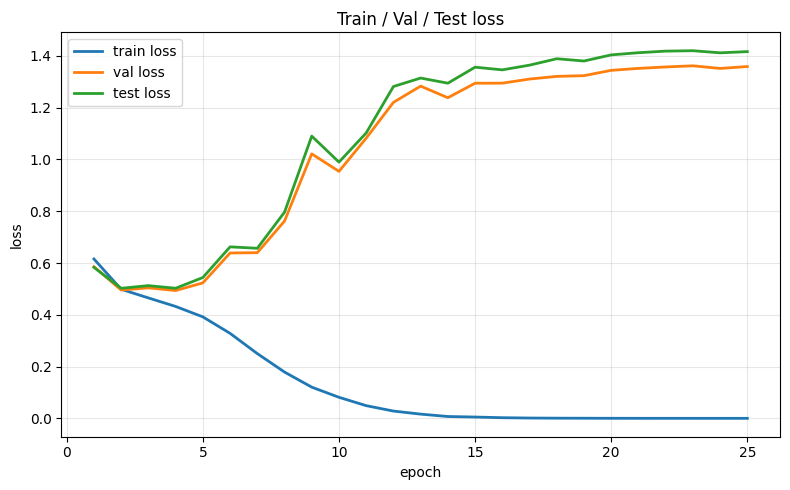

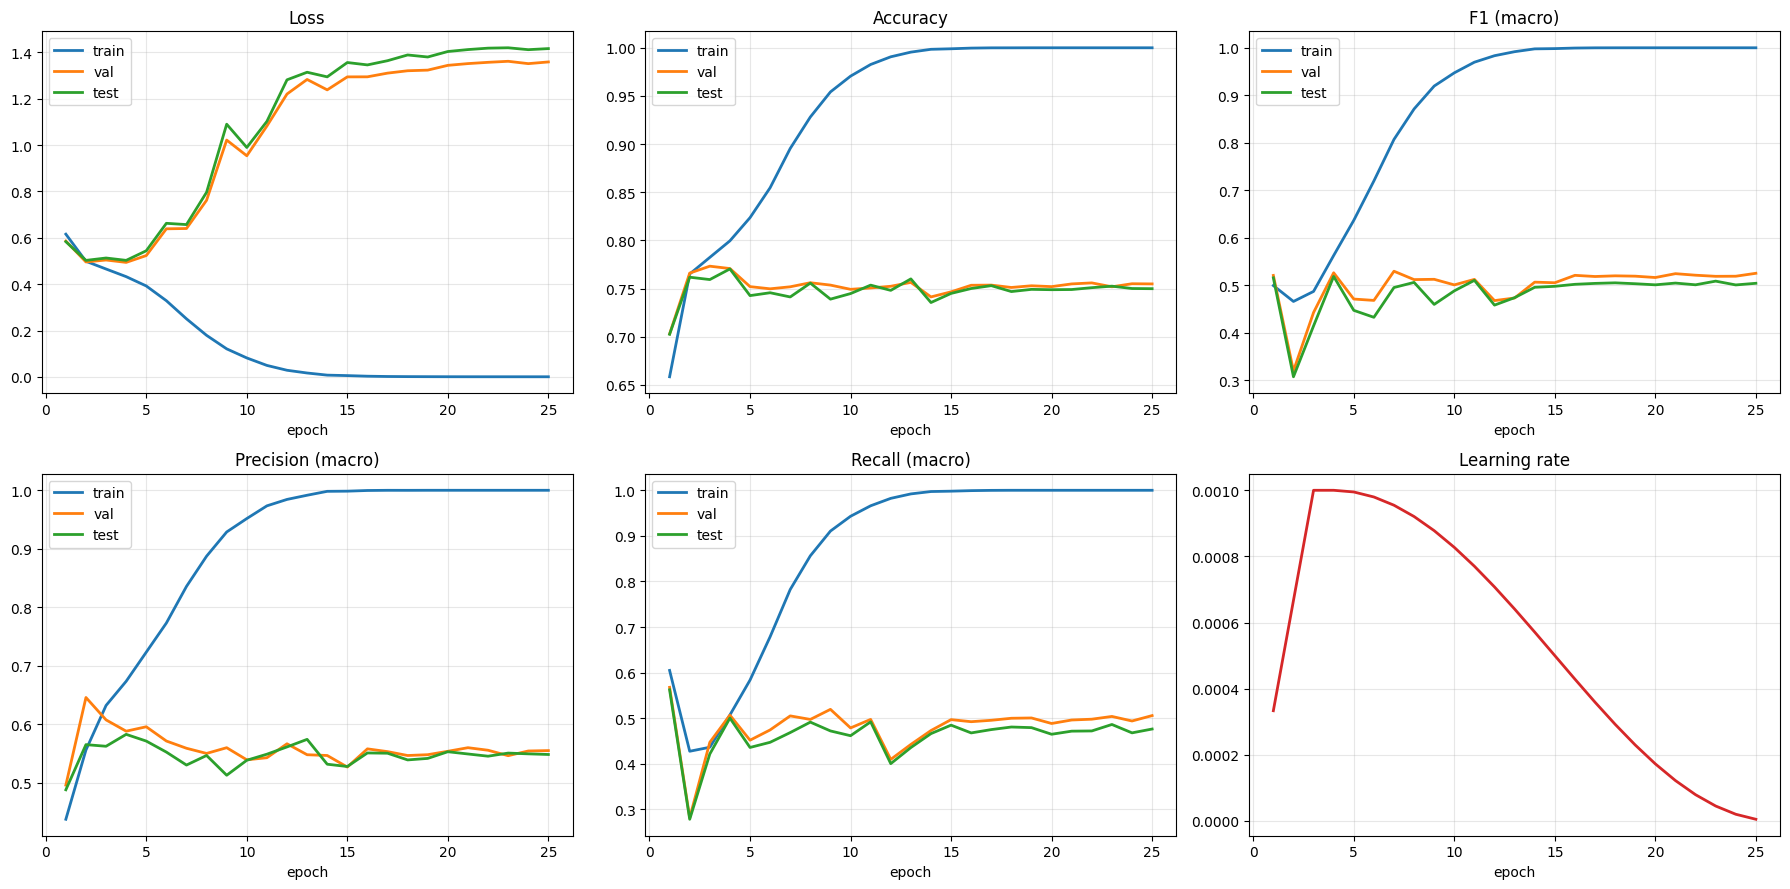

In [13]:
plot_loss_only(history)
plot_history(history, AVG)

## 8. Final evaluation (best-validation checkpoint)

In [14]:
import pandas as pd
res = {n: evaluate(model, l, criterion) for n, l in [("val", val_loader), ("test", test_loader)]}
rows = []
for n, (loss, y, p, prob) in res.items():
    m = metrics(y, p, AVG); m["loss"] = loss; m["auc"] = auc_score(y, prob); rows.append(pd.Series(m, name=n))
print(f"precision / recall / F1 = {AVG}-averaged")
print(pd.DataFrame(rows)[["loss", "acc", "precision", "recall", "f1", "auc"]].round(4))
_, ytest, ptest, probtest = res["test"]
print("\nTest classification report")
print(classification_report(ytest, ptest, target_names=CLASS_NAMES, digits=4, zero_division=0))

precision / recall / F1 = macro-averaged
        loss     acc  precision  recall      f1     auc
val   0.6400  0.7519     0.5588  0.5050  0.5296  0.7494
test  0.6569  0.7413     0.5301  0.4684  0.4953  0.7328

Test classification report
              precision    recall  f1-score   support

Cardiomegaly     0.4598    0.3902    0.4221       469
       Edema     0.7080    0.7072    0.7076       994
Pneumothorax     0.4225    0.3079    0.3562       354

   micro avg     0.6034    0.5476    0.5741      1817
   macro avg     0.5301    0.4684    0.4953      1817
weighted avg     0.5883    0.5476    0.5655      1817
 samples avg     0.4611    0.4564    0.4457      1817



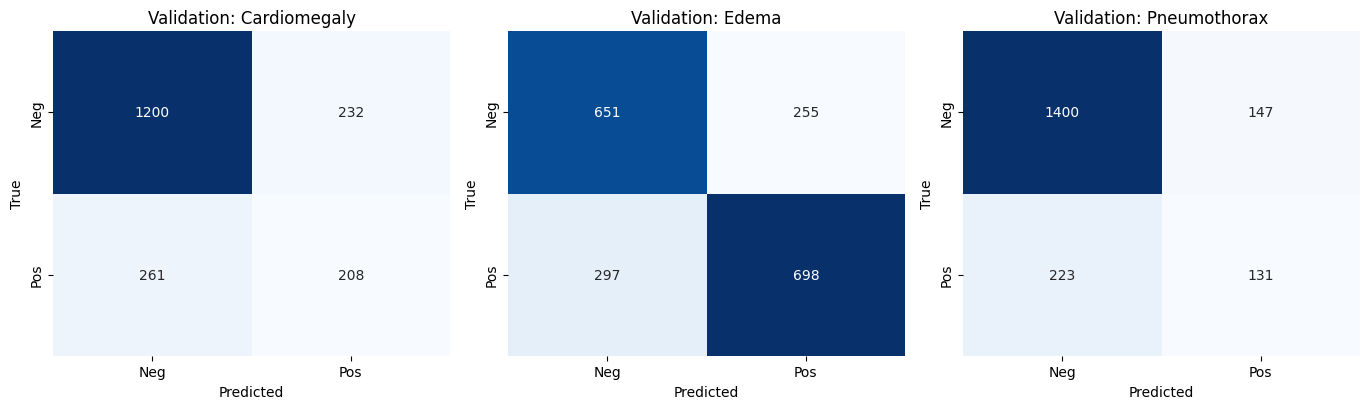

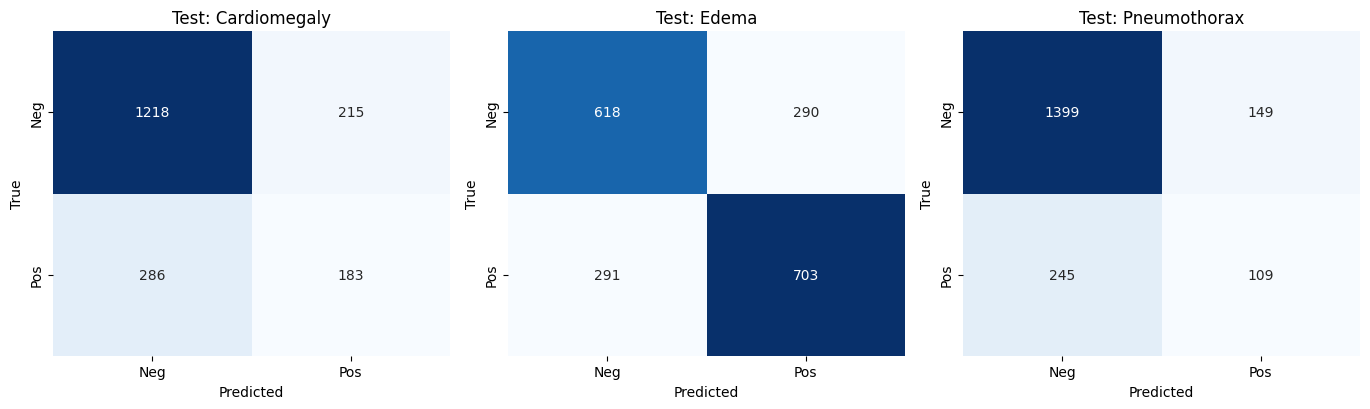

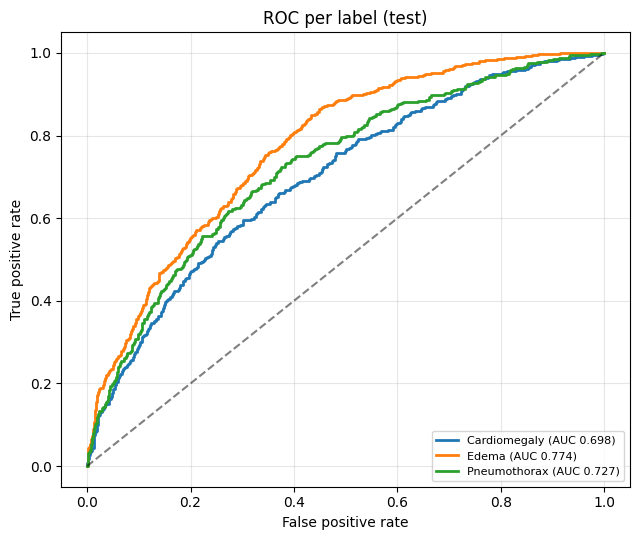

In [15]:
plot_confusion(res["val"][1], res["val"][2], CLASS_NAMES, "Validation", "confusion_val.png")
plot_confusion(ytest, ptest, CLASS_NAMES, "Test", "confusion_test.png")
plot_roc(ytest, probtest, CLASS_NAMES)

## Notes
- Plain training by default; set `USE_AUGMENTATION` / `USE_CLASS_WEIGHTS` at the top to change it.
- `VARIANT` M0-M5 selects the model size (Table 1). M2 is the default (about 4M parameters at 1000 classes).
- Images are decoded and resized once, kept in memory as uint8 and fed straight to the model, so there are no dataloader workers to crash.
- Best weights: `best_efficientvit.pt`; figures are saved as PNGs in the working directory.
- Multi-label task: precision / recall / F1 are macro-averaged over the 3 labels; accuracy is element-wise. Confusion matrices are one 2x2 per label; ROC is one curve per label.
- `DATA_DIR` must contain `metadata.csv` with a `new_path` column and one 0/1 column per label.
- Set `USE_CLASS_WEIGHTS=True` for a `pos_weight` in the BCE loss.